# Лабораторная работа 5. Итеративные и оптимизационные атаки: PGD, C&W, JSMA

**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам лекции 4**

**Формат:** индивидуально или в парах

**Среда:** Python, PyTorch, torchvision

## Цель работы
Закрепить методы построения многошаговых и оптимизационных evasion-атак и научиться сравнивать их по силе, вычислительной стоимости и величине вносимого искажения.

## Результаты обучения
После выполнения работы вы должны уметь:
- реализовывать PGD-атаку с проекцией на $L_\infty$-шар и случайным стартом;
- объяснять формулировку седловой точки (min-max) и её связь с adversarial training;
- реализовывать целевую C&W L2-атаку с заменой переменных через tanh и параметром confidence κ;
- реализовывать JSMA на основе якобиана выхода модели и точечного насыщения признаков;
- сравнивать атаки по Attack Success Rate, норме возмущения и вычислительным затратам.

## Как пользоваться этим ноутбуком
- Ячейки с `# TODO` необходимо заполнить самостоятельно.
- Ячейки с текстом **"Вопрос для отчёта"** требуют письменного ответа в markdown-ячейке ниже.
- Перед сдачей: Kernel → Restart & Run All, ноутбук должен выполняться от начала до конца без ошибок.
- Атаки на MNIST могут занимать заметное время на CPU (особенно JSMA) — рассчитывайте время выполнения заранее.


## 0. Подготовка окружения

In [ ]:
# TODO: импортируйте необходимые библиотеки
# Подсказка: numpy, matplotlib, torch, torch.nn, torch.nn.functional,
# torchvision (datasets, transforms), torch.utils.data.DataLoader

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

RANDOM_STATE = 42

# TODO: зафиксируйте seed для torch и numpy
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


Device: cpu


## Часть I. Данные и базовая модель

**Задание:** загрузите MNIST и обучите небольшую CNN (2 свёрточных слоя + полносвязный классификатор) — эта модель станет целью для всех атак в работе.

In [ ]:
# TODO: загрузите MNIST через torchvision.datasets

transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST(root='./data', train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False)

print(f"Train: {len(train_dataset)}, Test: {len(test_dataset)}")


100%|██████████| 9.91M/9.91M [00:00<00:00, 131MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 17.3MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 73.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.95MB/s]


Train: 60000, Test: 10000


In [ ]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # 2 свёрточных слоя + 2 пулинга + FC
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)    # 28x28x1 -> 28x28x32
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)   # 14x14x32 -> 14x14x64
        self.pool  = nn.MaxPool2d(2, 2)
        self.fc    = nn.Linear(64 * 7 * 7, 10)                      # 7x7x64 -> 10

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)                     # 28 -> 14
        x = F.relu(self.conv2(x))
        x = self.pool(x)                     # 14 -> 7
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

model = SmallCNN().to(device)
print(sum(p.numel() for p in model.parameters()), "параметров")


50186 параметров


In [ ]:
model = SmallCNN().to(device)
opt  = torch.optim.Adam(model.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()

EPOCHS = 3
for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        opt.zero_grad()
        logits = model(images)
        loss = crit(logits, labels)
        loss.backward()
        opt.step()

        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    print(f"Epoch {epoch+1}/{EPOCHS} | loss={running_loss/total:.4f} | acc={correct/total:.4f}")

Epoch 1/3 | loss=0.2496 | acc=0.9278
Epoch 2/3 | loss=0.0647 | acc=0.9805
Epoch 3/3 | loss=0.0474 | acc=0.9856


In [ ]:
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        correct += (model(images).argmax(1) == labels).sum().item()
        total += labels.size(0)
clean_accuracy = correct / total
print(f"Clean accuracy: {clean_accuracy:.4f}")


Clean accuracy: 0.9854


## Часть II. Projected Gradient Descent (PGD)

### 2.1. Реализация PGD

**Задание:** реализуйте функцию PGD-атаки по формуле

$ x^{t+1} = \Pi_{x+\mathcal{S}} \left( x^t + \alpha \cdot \text{sign}$nabla_x L$theta, x^t, y)) \right) $

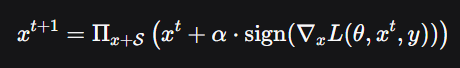

Функция должна:
1. Инициализировать возмущение случайно внутри \$epsilon$-шара (random start).
2. На каждой итерации пересчитывать градиент и делать шаг по знаку градиента.
3. Проецировать (clip) возмущение на \$epsilon$-шар и итоговый пиксель — на диапазон $[0,1]$.

In [ ]:
def pgd_attack(model, x, y, epsilon, alpha, num_iter, criterion, randomize=True):
    model.eval()

    # 1. Инициализация delta
    if randomize:
        delta = torch.empty_like(x).uniform_(-epsilon, epsilon)
    else:
        delta = torch.zeros_like(x)

    # Проекция стартового delta на допустимую область пикселей
    x_adv = torch.clamp(x + delta, 0.0, 1.0)
    delta = x_adv - x

    for _ in range(num_iter):
        delta = delta.clone().detach().requires_grad_(True)

        # Forward + backward
        logits = model(x + delta)
        loss = criterion(logits, y)
        model.zero_grad()
        loss.backward()

        with torch.no_grad():
            # Шаг по знаку градиента
            delta = delta + alpha * delta.grad.sign()
            # Проекция на ε-шар
            delta = torch.clamp(delta, -epsilon, epsilon)
            # Проекция на [0, 1]
            delta = torch.clamp(x + delta, 0.0, 1.0) - x

    return (x + delta).detach()

### 2.2. Визуализация: FGSM vs PGD

**Задание:** реализуйте FGSM (для сравнения), затем на одном тестовом примере постройте adversarial-версии обоими методами при одинаковом \$epsilon$ и визуализируйте результат (3 подграфика: оригинал, FGSM, PGD) с указанием предсказаний модели.

In [ ]:
def fgsm_attack(model, x, y, epsilon, criterion):
    model.eval()
    x_adv = x.clone().detach().requires_grad_(True)
    logits = model(x_adv)
    loss = criterion(logits, y)
    model.zero_grad()
    loss.backward()
    with torch.no_grad():
        x_adv = x_adv + epsilon * x_adv.grad.sign()
        x_adv = torch.clamp(x_adv, 0.0, 1.0)
    return x_adv.detach()


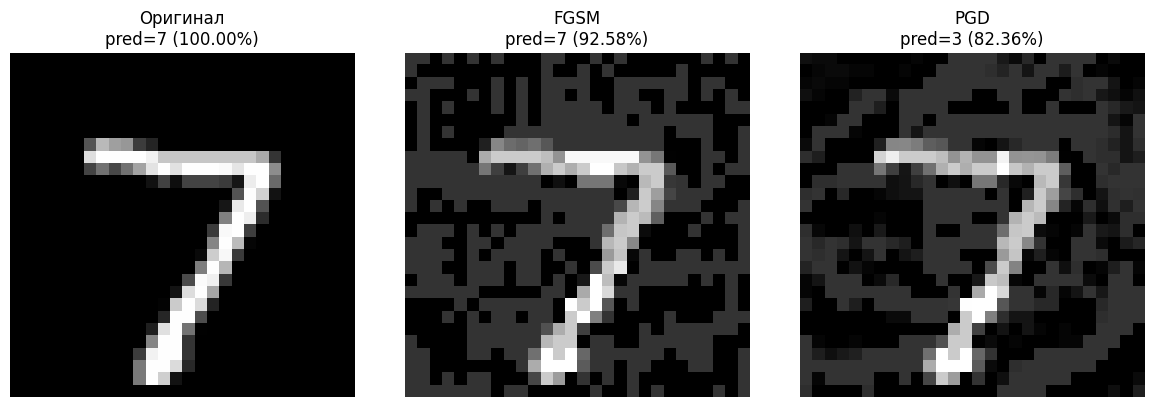

In [ ]:
# TODO: выберите тестовый пример
# TODO: примените fgsm_attack и pgd_attack с epsilon=0.2 (для PGD: alpha=0.02, num_iter=40)
# TODO: постройте визуализацию из 3 подграфиков с предсказаниями модели

# Возьмём один тестовый пример
model.eval()
images, labels = next(iter(test_loader))
idx = 0
x = images[idx:idx+1].to(device)
y = labels[idx:idx+1].to(device)

epsilon = 0.2

x_fgsm = fgsm_attack(model, x, y, epsilon, crit)
x_pgd  = pgd_attack(model, x, y, epsilon, alpha=0.02, num_iter=40, criterion=crit)

with torch.no_grad():
    p_clean = F.softmax(model(x),     1)[0]
    p_fgsm  = F.softmax(model(x_fgsm),1)[0]
    p_pgd   = F.softmax(model(x_pgd), 1)[0]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(x.cpu().squeeze(), cmap='gray')
axes[0].set_title(f"Оригинал\npred={p_clean.argmax().item()} ({p_clean.max():.2%})")
axes[1].imshow(x_fgsm.cpu().squeeze(), cmap='gray')
axes[1].set_title(f"FGSM\npred={p_fgsm.argmax().item()} ({p_fgsm.max():.2%})")
axes[2].imshow(x_pgd.cpu().squeeze(), cmap='gray')
axes[2].set_title(f"PGD\npred={p_pgd.argmax().item()} ({p_pgd.max():.2%})")
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()


**Вопрос для отчёта:** отличаются ли визуально возмущения FGSM и PGD? Какой метод успешнее меняет предсказание модели при одном и том же ε?

_Ваш ответ:_ Визуально возмущения FGSM и PGD при ε=0.2 похожи, но PGD более сормированный шум. PGD лучше справляется

### 2.3. Attack Success Rate: FGSM vs PGD

**Задание:** постройте график зависимости Attack Success Rate от бюджета $\epsilon \in \{0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3\}$ для FGSM и PGD (20 итераций) на одном графике.

ε=0.02 | FGSM=0.0156 | PGD=0.0172
ε=0.05 | FGSM=0.0445 | PGD=0.0598
ε=0.10 | FGSM=0.1570 | PGD=0.2648
ε=0.15 | FGSM=0.3602 | PGD=0.6602
ε=0.20 | FGSM=0.6137 | PGD=0.9578
ε=0.30 | FGSM=0.9496 | PGD=0.9801


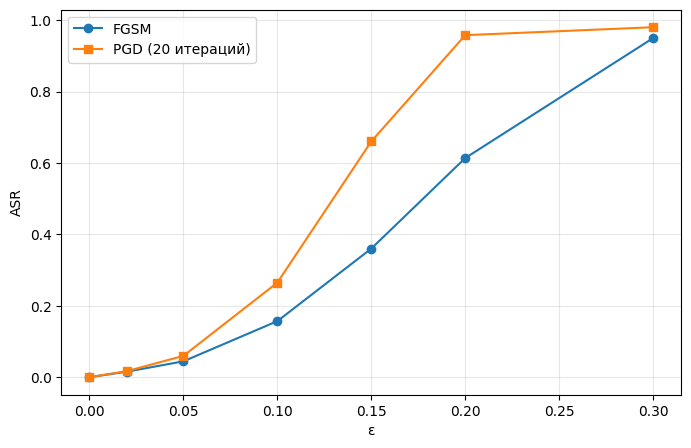

In [ ]:
# TODO: реализуйте функцию оценки ASR на подмножестве тестовой выборки
def evaluate_asr(model, loader, attack_fn, criterion, n_batches=10, **attack_kwargs):
    model.eval()
    total, changed = 0, 0
    for i, (images, labels) in enumerate(loader):
        if i >= n_batches: break
        images, labels = images.to(device), labels.to(device)
        with torch.no_grad():
            pred_clean = model(images).argmax(1)
        x_adv = attack_fn(model, images, labels, criterion=criterion, **attack_kwargs)
        with torch.no_grad():
            pred_adv = model(x_adv).argmax(1)
        changed += (pred_clean != pred_adv).sum().item()
        total += labels.size(0)
    return changed / total

epsilons = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
asr_fgsm, asr_pgd = [], []

for eps in epsilons:
    if eps == 0.0:
        asr_fgsm.append(0.0); asr_pgd.append(0.0); continue
    asr_fgsm.append(evaluate_asr(model, test_loader, fgsm_attack, crit, 10,
                                 epsilon=eps))
    asr_pgd.append( evaluate_asr(model, test_loader, pgd_attack,  crit, 10,
                                 epsilon=eps, alpha=eps/10, num_iter=20))
    print(f"ε={eps:.2f} | FGSM={asr_fgsm[-1]:.4f} | PGD={asr_pgd[-1]:.4f}")

plt.figure(figsize=(8,5))
plt.plot(epsilons, asr_fgsm, marker='o', label="FGSM")
plt.plot(epsilons, asr_pgd,  marker='s', label="PGD (20 итераций)")
plt.xlabel("ε"); plt.ylabel("ASR"); plt.grid(alpha=0.3); plt.legend(); plt.show()


### 2.4. Влияние числа итераций PGD

**Задание:** зафиксируйте $\epsilon = 0.15$ и постройте график зависимости ASR от числа итераций PGD $\in \{1, 2, 5, 10, 20, 40, 80\}$. Определите, при каком числе итераций ASR стабилизируется (перестаёт заметно расти).

iter=  1 | ASR=0.0187
iter=  2 | ASR=0.0398
iter=  5 | ASR=0.1734
iter= 10 | ASR=0.5117
iter= 20 | ASR=0.6586
iter= 40 | ASR=0.6906
iter= 80 | ASR=0.6969


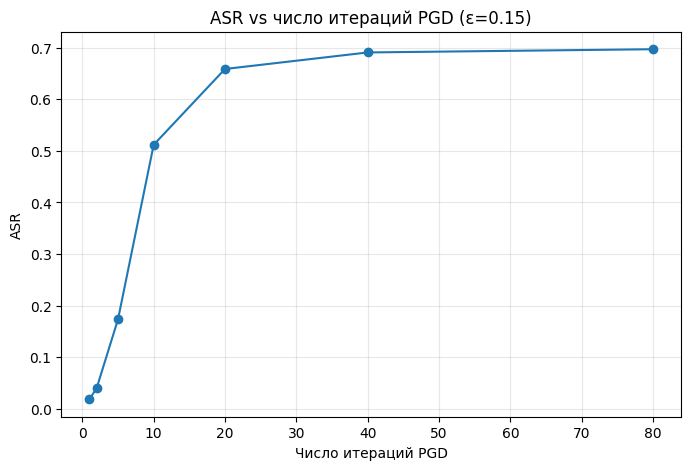

In [ ]:
# TODO: рассчитайте ASR для разного числа итераций PGD при фиксированном epsilon=0.15
# TODO: постройте график
iters = [1, 2, 5, 10, 20, 40, 80]
asr_iters = []
for n in iters:
    asr = evaluate_asr(model, test_loader, pgd_attack, crit, 10,
                       epsilon=0.15, alpha=0.15/10, num_iter=n)
    asr_iters.append(asr)
    print(f"iter={n:>3} | ASR={asr:.4f}")

plt.figure(figsize=(8,5))
plt.plot(iters, asr_iters, marker='o')
plt.xlabel("Число итераций PGD"); plt.ylabel("ASR")
plt.title("ASR vs число итераций PGD (ε=0.15)")
plt.grid(alpha=0.3); plt.show()

**Вопрос для отчёта:** при каком числе итераций ASR практически перестаёт расти? Как это соотносится с утверждением лекции о том, что одношаговая линеаризация (FGSM) даёт лишь нижнюю оценку силы атаки?

_Ваш ответ:_ 40 итераций, соотносится, так как FGSM является лишь первым шагом в PGD, однако стоит учитывать размер шага

### 2.5. Adversarial training через PGD (седловая точка)

**Задание:** обучите вторую модель с adversarial training по формулировке седловой точки Мадри:

$\min_{\theta} \mathbb{E}_{(x,y)} \left[ \max_{\delta \in \mathcal{S}} L$theta, x+\delta, y) \right] $

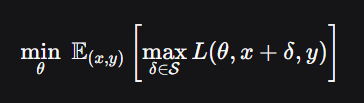

На каждом шаге обучения внутренний максимум приближайте PGD с небольшим числом итераций (5-7), а внешний шаг оптимизации делайте по параметрам модели на полученных adversarial-примерах.

In [ ]:
# TODO: реализуйте цикл adversarial training
# На каждом батче:
# 1. Постройте x_adv через pgd_attack (5-7 итераций, epsilon=0.15)
# 2. Посчитайте loss на x_adv
# 3. Сделайте шаг оптимизации

adv_model = SmallCNN().to(device)
opt_adv = torch.optim.Adam(adv_model.parameters(), lr=1e-3)

EPOCHS_ADV = 3
EPS_TRAIN = 0.15

for epoch in range(EPOCHS_ADV):
    adv_model.train()
    run_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Внутренний max: PGD с 5 итерациями
        x_adv = pgd_attack(adv_model, images, labels,
                           epsilon=EPS_TRAIN, alpha=EPS_TRAIN/5,
                           num_iter=5, criterion=crit, randomize=True)

        # Внешний min: обновляем веса
        opt_adv.zero_grad()
        logits = adv_model(x_adv)
        loss = crit(logits, labels)
        loss.backward()
        opt_adv.step()

        run_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    print(f"Epoch {epoch+1} | adv_loss={run_loss/total:.4f} | adv_acc={correct/total:.4f}")

# Clean accuracy adv-модели
adv_model.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        correct += (adv_model(images).argmax(1) == labels).sum().item()
        total += labels.size(0)
print(f"Adv clean accuracy: {correct/total:.4f}")


Epoch 1 | adv_loss=0.5910 | adv_acc=0.8027
Epoch 2 | adv_loss=0.2813 | adv_acc=0.9077
Epoch 3 | adv_loss=0.2394 | adv_acc=0.9212
Adv clean accuracy: 0.9835


ε=0.02 | adv-FGSM=0.0047 | adv-PGD=0.0055
ε=0.05 | adv-FGSM=0.0187 | adv-PGD=0.0191
ε=0.10 | adv-FGSM=0.0402 | adv-PGD=0.0461
ε=0.15 | adv-FGSM=0.0727 | adv-PGD=0.0980
ε=0.20 | adv-FGSM=0.1047 | adv-PGD=0.2621
ε=0.30 | adv-FGSM=0.2348 | adv-PGD=0.9734


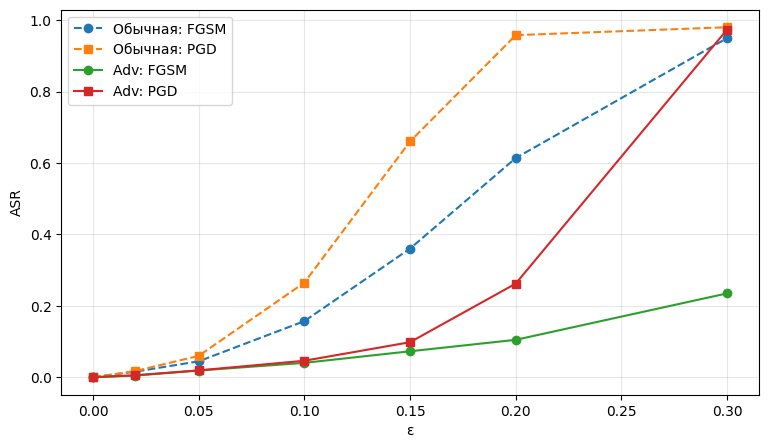

In [ ]:
# TODO: постройте график ASR(epsilon) для adv_model против FGSM и против PGD
# Сравните на одном графике с результатами обычной модели из п.2.3

asr_adv_fgsm, asr_adv_pgd = [], []
for eps in epsilons:
    if eps == 0.0:
        asr_adv_fgsm.append(0.0); asr_adv_pgd.append(0.0); continue
    asr_adv_fgsm.append(evaluate_asr(adv_model, test_loader, fgsm_attack, crit, 10, epsilon=eps))
    asr_adv_pgd.append( evaluate_asr(adv_model, test_loader, pgd_attack,  crit, 10,
                                     epsilon=eps, alpha=eps/10, num_iter=40))
    print(f"ε={eps:.2f} | adv-FGSM={asr_adv_fgsm[-1]:.4f} | adv-PGD={asr_adv_pgd[-1]:.4f}")

plt.figure(figsize=(9,5))
plt.plot(epsilons, asr_fgsm, 'o--', label="Обычная: FGSM")
plt.plot(epsilons, asr_pgd,  's--', label="Обычная: PGD")
plt.plot(epsilons, asr_adv_fgsm, 'o-', label="Adv: FGSM")
plt.plot(epsilons, asr_adv_pgd,  's-', label="Adv: PGD")
plt.xlabel("ε"); plt.ylabel("ASR"); plt.grid(alpha=0.3); plt.legend(); plt.show()

**Вопрос для отчёта:** насколько снизился ASR против PGD и против FGSM после adversarial training? Согласуется ли результат с идеей «универсального первопорядкового противника» — устойчивость к PGD переносится на устойчивость к более слабым атакам?

_Ваш ответ:_ снизился в разы после адв обучения. Устойчивость переносится, это видно на графике (адв обученная на PGD модель устойчива и к FGSM)

## Часть III. Атака Carlini & Wagner (C&W)

### 3.1. Реализация целевой C&W L2-атаки

**Задание:** реализуйте C&W-атаку (вариант L2, целевая) по следующей схеме:

1. Замена переменных: $ x' = \frac{1}{2}\tanh(w)+1) $ — гарантирует $x' \in [0,1]$ без явного clipping.
2. Функция потерь на логитах с параметром confidence κ:
$ f(x') = \max\left( \max_{i \ne t} Z(x')_i - Z(x')_t,\; -\kappa \right) $
3. Итоговая целевая функция:

$ \min_{w} \left\| \tfrac{1}{2}(\tanh(w)+1) - x \right\|_2^2 + c \cdot f\left(\tfrac{1}{2}(\tanh(w)+1)\right) $

4. Оптимизация через Adam по переменной $w$.

In [ ]:
def cw_l2_attack(model, x, target_class, c=1.0, kappa=0.0, num_steps=200, lr=0.01):
    model.eval()

    # 1. Инициализация w = atanh(2x - 1), с зажимом в допустимый диапазон
    x_clamped = torch.clamp(x, 1e-6, 1 - 1e-6)
    w = torch.atanh(2 * x_clamped - 1).clone().detach().requires_grad_(True)

    optimizer = torch.optim.Adam([w], lr=lr)

    target_tensor = torch.tensor([target_class], device=x.device)

    for step in range(num_steps):
        x_adv = 0.5 * (torch.tanh(w) + 1)

        logits = model(x_adv)
        # логит целевого класса
        target_logit = logits[0, target_class]
        # лучший логит среди остальных
        other = logits.clone()
        other[0, target_class] = -float('inf')
        best_other = other.max()

        # f(x') = max(best_other - target_logit, -kappa)
        f_loss = torch.clamp(best_other - target_logit, min=-kappa)

        # L2-возмущение
        dist_loss = ((x_adv - x) ** 2).sum()

        loss = dist_loss + c * f_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        x_adv = 0.5 * (torch.tanh(w) + 1)
    return x_adv.detach()


### 3.2. Демонстрация целевой атаки

**Задание:** выберите тестовый пример и целевой класс (отличный от истинного), постройте adversarial-пример методом C&W (κ=0) и визуализируйте: оригинал, возмущение (с указанием L2-нормы), adversarial-пример (с предсказанием и confidence).

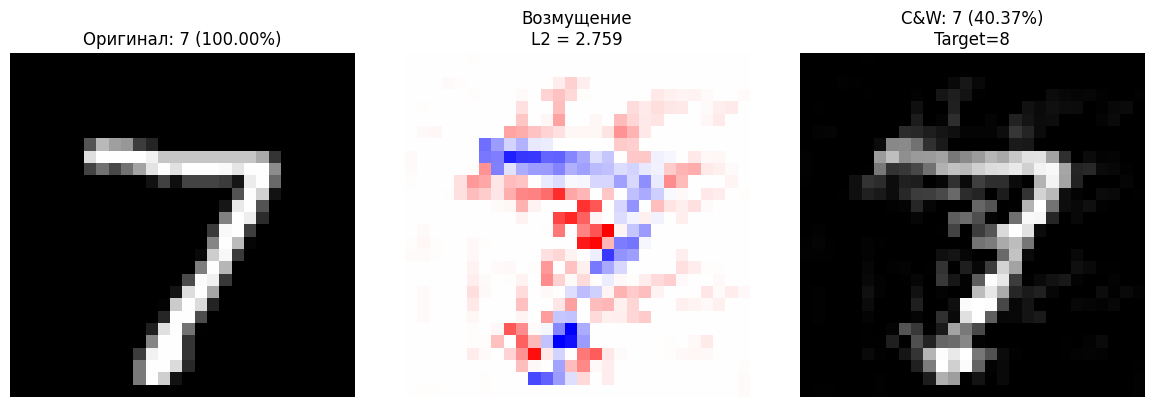

L2-норма: 2.7586


In [ ]:
# TODO: выберите пример, задайте target_label
# TODO: примените cw_l2_attack
# TODO: визуализируйте результат, рассчитайте L2-норму возмущения
model.eval()
images, labels = next(iter(test_loader))
idx = 0
x = images[idx:idx+1].to(device)
y_true = labels[idx].item()
target_label = 8 if y_true != 8 else 3

x_cw = cw_l2_attack(model, x, target_label, c=1.0, kappa=0, num_steps=300, lr=0.01)

with torch.no_grad():
    p_clean = F.softmax(model(x),    1)[0]
    p_cw    = F.softmax(model(x_cw), 1)[0]

l2 = ((x_cw - x)**2).sum().sqrt().item()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(x.cpu().squeeze(), cmap='gray')
axes[0].set_title(f"Оригинал: {p_clean.argmax().item()} ({p_clean.max():.2%})")
axes[1].imshow((x_cw - x).cpu().squeeze(), cmap='bwr',
               vmin=-0.5, vmax=0.5)
axes[1].set_title(f"Возмущение\nL2 = {l2:.3f}")
axes[2].imshow(x_cw.cpu().squeeze(), cmap='gray')
axes[2].set_title(f"C&W: {p_cw.argmax().item()} ({p_cw.max():.2%})\nTarget={target_label}")
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

print(f"L2-норма: {l2:.4f}")

### 3.3. Влияние параметра confidence κ

**Задание:** для того же примера постройте C&W-атаки с κ ∈ {0, 5, 10, 20, 40} и постройте два графика: (а) зависимость L2-нормы возмущения от κ, (б) зависимость вероятности целевого класса от κ.

κ=  0 | L2=3.3338 | P(target)=0.3158
κ=  5 | L2=3.9179 | P(target)=0.8559
κ= 10 | L2=3.9179 | P(target)=0.8559
κ= 20 | L2=3.9179 | P(target)=0.8559
κ= 40 | L2=3.9179 | P(target)=0.8559


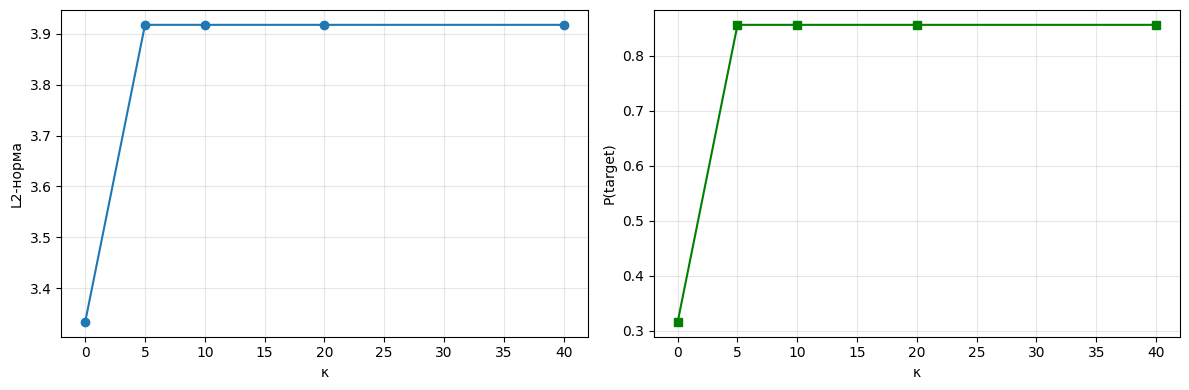

In [ ]:
# TODO: постройте атаки для разных значений kappa
# TODO: постройте два графика (L2-норма и confidence целевого класса от kappa)
kappas = [0, 5, 10, 20, 40]
l2_norms, target_probs = [], []

for k in kappas:
    x_cw = cw_l2_attack(model, x, target_label, c=2.0, kappa=k, num_steps=300, lr=0.01)
    l2 = ((x_cw - x)**2).sum().sqrt().item()
    with torch.no_grad():
        p = F.softmax(model(x_cw), 1)[0]
    l2_norms.append(l2)
    target_probs.append(p[target_label].item())
    print(f"κ={k:>3} | L2={l2:.4f} | P(target)={target_probs[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(kappas, l2_norms, marker='o')
axes[0].set_xlabel("κ"); axes[0].set_ylabel("L2-норма"); axes[0].grid(alpha=0.3)
axes[1].plot(kappas, target_probs, marker='s', color='green')
axes[1].set_xlabel("κ"); axes[1].set_ylabel("P(target)"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Вопрос для отчёта:** как изменяется величина возмущения при росте κ? Объясните этот эффект, опираясь на формулу функции потерь $f(x')$ из лекции.

_Ваш ответ:_ L2 растёт от κ=0 к κ=5, потому что формула
f требует большей уверенности (разрыв ≥ κ). Но с κ=10 и выше
f перестаёт "зажиматься" — оптимизатор уже достиг нужного разрыва, и при c=2 не видит смысла дожимать дальше.

## Часть IV. Jacobian-based Saliency Map Attack (JSMA)

### 4.1. Реализация JSMA

**Задание:** реализуйте целевую JSMA-атаку по следующей схеме:

1. Вычислите якобиан выходных вероятностей модели по входу (для всех 10 классов).
2. Постройте saliency-карту: произведение градиента целевого класса и (с обратным знаком) суммарного градиента остальных классов, отбирая только те пиксели, где рост значения пикселя увеличивает вероятность целевого класса и одновременно уменьшает вероятность остальных.
3. На каждой итерации выберите пиксель с максимальной saliency, "насытите" его значение (увеличьте до предела, например, на величину θ=1.0), исключите уже изменённые и предельные пиксели из дальнейшего рассмотрения.
4. Повторяйте, пока не будет достигнута целевая классификация или не будет исчерпан лимит `max_pixels`.

In [ ]:
# TODO: реализуйте функцию вычисления якобиана
def compute_jacobian(model, x, num_classes=10):
    """
    x: [1, 1, 28, 28]
    Возвращает: [num_classes, 1, 28, 28] — градиент softmax-вероятности каждого класса по входу
    """
    model.eval()
    x_req = x.clone().detach().requires_grad_(True)
    logits = model(x_req)
    probs = F.softmax(logits, dim=1)   # [1, 10]

    jacobian = torch.zeros(num_classes, *x.shape[1:], device=x.device)
    for c in range(num_classes):
        # grad_outputs: "единичка" на позиции c
        grad = torch.autograd.grad(probs[0, c], x_req,
                                   retain_graph=True, create_graph=False)[0]
        jacobian[c] = grad.squeeze(0)
    return jacobian


In [ ]:
# TODO: реализуйте функцию JSMA-атаки
def jsma_attack(model, x, target_class, max_pixels=60, theta=1.0):
    model.eval()
    x_adv = x.clone().detach()
    # маска изменённых/насыщенных пикселей (форма одного изображения)
    modified = torch.zeros_like(x_adv[0, 0], dtype=torch.bool)

    for step in range(max_pixels):
        # Проверка: достигли ли целевого класса
        with torch.no_grad():
            pred = model(x_adv).argmax(1).item()
        if pred == target_class:
            break

        # Якобиан: [10, 1, 28, 28]
        J = compute_jacobian(model, x_adv, num_classes=10)
        # Убираем размерность канала (канал 1 для MNIST)
        J = J[:, 0]   # [10, 28, 28]

        target_grad = J[target_class]                     # [28, 28]
        # сумма по всем остальным классам
        other_grad = J.sum(dim=0) - target_grad           # [28, 28]

        # Saliency: только там, где target_grad > 0 и other_grad < 0
        mask = (target_grad > 0) & (other_grad < 0)
        saliency = torch.where(mask,
                               target_grad * other_grad.abs(),
                               torch.zeros_like(target_grad))

        # Исключаем уже изменённые и почти насыщенные пиксели
        saturated = x_adv[0, 0] >= 0.99
        saliency = saliency.masked_fill(modified | saturated, -float('inf'))

        # Если всё замаскировано — выход
        if torch.isinf(saliency).all():
            break

        # Топ-1 пиксель
        idx_flat = saliency.argmax().item()
        i, j = np.unravel_index(idx_flat, saliency.shape)

        # Обновляем пиксель
        with torch.no_grad():
            x_adv[0, 0, i, j] = torch.clamp(x_adv[0, 0, i, j] + theta, 0.0, 1.0)
        modified[i, j] = True

    n_modified = modified.sum().item()
    return x_adv.detach(), n_modified


### 4.2. Демонстрация точечной атаки

**Задание:** для того же примера и целевого класса, что и в п.3.2, постройте JSMA-атаку и визуализируйте: оригинал, карту изменённых пикселей, adversarial-пример (с предсказанием модели и числом изменённых пикселей).

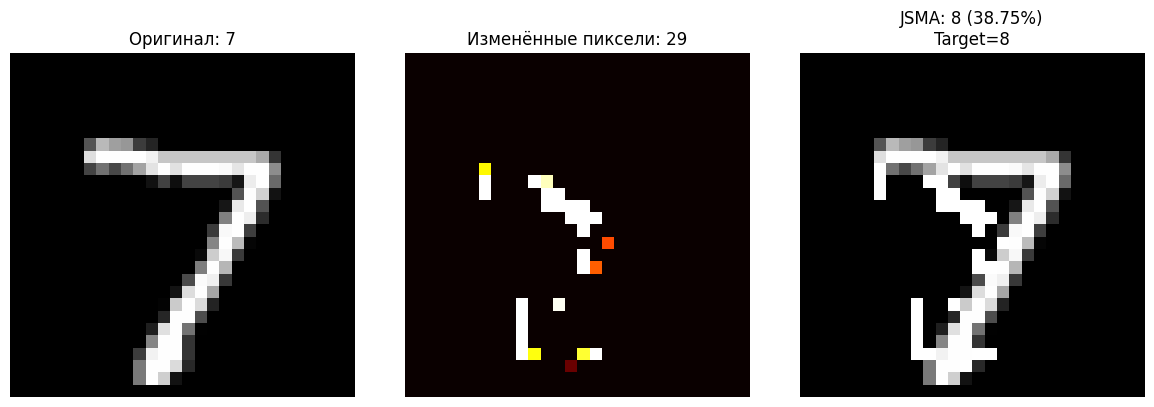

Изменено пикселей: 29 из 784 (3.70%)


In [ ]:
# TODO: примените jsma_attack к тому же примеру и target_label из части III
# TODO: визуализируйте результат (3 подграфика)
x_jsma, n_pix = jsma_attack(model, x, target_label, max_pixels=60, theta=1.0)

with torch.no_grad():
    p_jsma = F.softmax(model(x_jsma), 1)[0]

diff_map = (x_jsma - x).abs().cpu().squeeze()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(x.cpu().squeeze(), cmap='gray')
axes[0].set_title(f"Оригинал: {p_clean.argmax().item()}")
axes[1].imshow(diff_map, cmap='hot')
axes[1].set_title(f"Изменённые пиксели: {n_pix}")
axes[2].imshow(x_jsma.cpu().squeeze(), cmap='gray')
axes[2].set_title(f"JSMA: {p_jsma.argmax().item()} ({p_jsma.max():.2%})\nTarget={target_label}")
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

print(f"Изменено пикселей: {n_pix} из 784 ({n_pix/784*100:.2f}%)")

**Вопрос для отчёта:** сколько пикселей потребовалось изменить для успешной атаки? Насколько это число мало по сравнению с общим числом пикселей изображения (28×28=784)?

_Ваш ответ:_ 29 пикселей всего


## Часть V. Итоговое сравнение атак

**Задание:** для одного и того же исходного изображения и целевого класса постройте атаки всеми тремя методами (целевой PGD, C&W, JSMA) и сравните их в таблице по следующим критериям:
- успешность (достигнут ли целевой класс);
- L2-норма возмущения;
- L∞-норма возмущения;
- число изменённых пикселей (порог изменения > 1e-3).

Постройте также столбчатую диаграмму, сравнивающую три атаки по каждому из трёх числовых критериев.

In [ ]:
# TODO: реализуйте функцию целевой PGD-атаки (минимизация loss к целевому классу вместо максимизации к истинному)
def pgd_targeted(model, x, target, epsilon, alpha, num_iter, criterion):
    """
    Целевая PGD: минимизируем loss по целевому классу (target).
    """
    model.eval()
    delta = torch.empty_like(x).uniform_(-epsilon, epsilon)
    x_adv = torch.clamp(x + delta, 0.0, 1.0)
    delta = x_adv - x

    target_tensor = torch.full_like(target, fill_value=int(target[0])) if target.dim() > 0 else target

    for _ in range(num_iter):
        delta = delta.clone().detach().requires_grad_(True)
        logits = model(x + delta)
        loss = criterion(logits, target)   # минимизируем (а не максимизируем)
        model.zero_grad()
        loss.backward()

        with torch.no_grad():
            delta = delta - alpha * delta.grad.sign()   # МИНУС (идём к целевому классу)
            delta = torch.clamp(delta, -epsilon, epsilon)
            delta = torch.clamp(x + delta, 0.0, 1.0) - x

    return (x + delta).detach()


In [ ]:
# TODO: постройте атаки всеми тремя методами для одного примера и одного target_label
# TODO: соберите результаты в pandas DataFrame (метод, успех, предсказание, L2, Linf, число пикселей)
# TODO: сохраните таблицу в CSV
import pandas as pd

x = x.to(device)
y_target_tensor = torch.tensor([target_label], device=device)

# Целевой PGD
x_pgd_t = pgd_targeted(model, x, y_target_tensor,
                       epsilon=0.2, alpha=0.02, num_iter=40, criterion=crit)
# C&W (уже посчитан x_cw, kappa=0)
x_cw_t = x_cw
# JSMA (уже посчитан)
x_jsma_t = x_jsma

def analyze(name, x_o, x_a, target):
    with torch.no_grad():
        pred = model(x_a).argmax(1).item()
    diff = (x_a - x_o).detach()
    l2 = diff.pow(2).sum().sqrt().item()
    linf = diff.abs().max().item()
    n_pix = (diff.abs() > 1e-3).sum().item()
    return {"method": name, "success": pred == target, "pred": pred,
            "L2": l2, "Linf": linf, "n_pixels": n_pix}

rows = [
    analyze("Targeted PGD", x, x_pgd_t, target_label),
    analyze("C&W L2",       x, x_cw_t,  target_label),
    analyze("JSMA",         x, x_jsma_t,target_label),
]

df = pd.DataFrame(rows)
print(df.to_string(index=False))
df.to_csv("attack_comparison.csv", index=False)


      method  success  pred       L2     Linf  n_pixels
Targeted PGD    False     7 4.058870 0.200000       547
      C&W L2     True     8 3.917889 0.707672       347
        JSMA     True     8 5.010843 1.000000        29


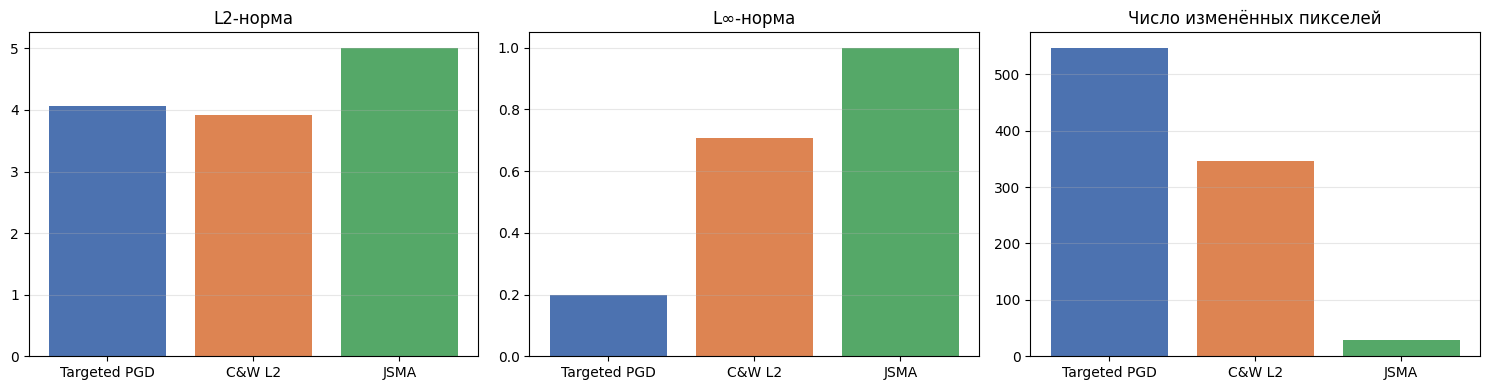

In [ ]:
# TODO: постройте столбчатую диаграмму из 3 подграфиков (L2, Linf, число изменённых пикселей)
# для трёх методов
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics = ["L2", "Linf", "n_pixels"]
titles  = ["L2-норма", "L∞-норма", "Число изменённых пикселей"]

for ax, m, t in zip(axes, metrics, titles):
    ax.bar(df["method"], df[m], color=["#4C72B0", "#DD8452", "#55A868"])
    ax.set_title(t)
    ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

**Вопрос для отчёта:** какой метод дал наименьшую L2-норму возмущения? Какой — наименьшее число изменённых пикселей? Объясните разницу, опираясь на то, какую норму возмущения оптимизирует каждый метод по своей природе.

_Ваш ответ:_ Все соотнгосится с тем на основе какой нормы работает тот или иной оптимизированный метод атаки

## Часть VI. Итоговый вывод

**Вопрос для отчёта:** сформулируйте общий вывод о трёх изученных методах атак. Почему PGD считается «универсальным первопорядковым противником» и стандартом для adversarial training, тогда как C&W чаще используется как эталон для проверки устойчивости защитных механизмов, а JSMA — как инструмент, ценный своей интерпретируемостью и разреженностью возмущения? В каких прикладных сценариях (например, атаки на изображения высокого разрешения, на табличные данные, на системы обнаружения вторжений) предпочтителен каждый из методов?

_Ваш ответ:_ PGD — универсальный первопорядковый противник: устойчивость к нему переносится на все L∞-атаки, поэтому он стандарт для adversarial training. C&W — эталон для проверки защит: ищет минимальное L2-возмущение с заданной уверенностью, дорогой, но точный. JSMA — инструмент для разреженных атак: меняет мало пикселей, ценен интерпретируемостью.

Применение: PGD — изображения высокого разрешения (быстро, L∞-бюджет); JSMA — табличные данные (мало признаков); C&W — системы обнаружения вторжений и бенчмарки защит (минимальное суммарное отклонение).

---
Выполните **не менее двух** из следующих заданий. Оформите результаты в отдельных ячейках ниже с пометкой `# ДЛЯ СИЛЬНЫХ СТУДЕНТОВ`.

### С1. PGD с разными нормами
Реализуйте вариант PGD-атаки с проекцией на $L_2$-шар вместо $L_\infty$ (нормализация градиента по L2-норме на каждом шаге с последующим масштабированием под бюджет ε). Сравните визуально и по ASR с исходным $L_\infty$-вариантом.

### С2. Ускоренная (Maximal) JSMA
Изучите идею ускоренных версий JSMA (например, приближение сложности с $O(M^2 N)$ до $O(M\sqrt{N})$ за счёт эвристического отбора кандидатов вместо полного перебора). Реализуйте упрощённую версию с случайной подвыборкой кандидатов на каждой итерации и сравните скорость и качество атаки с полной версией из Части IV.

### С3. Перенос устойчивости между атаками (adversarial training cross-attack)
Обучите модель с adversarial training на PGD (Часть 2.5). Проверьте её устойчивость не только к PGD и FGSM, но и к C&W и JSMA. Обсудите, перенеслась ли устойчивость на оптимизационные и разреженные атаки, которые не участвовали в обучении.

### С4. Влияние константы c в C&W
Исследуйте, как выбор константы $c$ в целевой функции C&W (без бинарного поиска, вручную для нескольких значений: 0.1, 1, 10, 100) влияет на баланс между успешностью атаки и величиной L2-искажения. Постройте график Success Rate и средней L2-нормы в зависимости от $c$ на нескольких тестовых примерах.


In [ ]:
# ДЛЯ СИЛЬНЫХ СТУДЕНТОВ
# TODO: реализуйте выбранные задания (С1-С4) здесь

# C3

N_EVAL = 30   # маленькое подмножество — C&W и JSMA очень медленные

def get_eval_subset(loader, n):
    xs, ys = [], []
    for images, labels in loader:
        xs.append(images); ys.append(labels)
        if sum(t.size(0) for t in xs) >= n:
            break
    x = torch.cat(xs, 0)[:n].to(device)
    y = torch.cat(ys, 0)[:n].to(device)
    return x, y

x_eval, y_eval = get_eval_subset(test_loader, N_EVAL)


def asr_untargeted(model, x, y, attack_name, epsilon=0.15, **kwargs):
    """ASR для обычных (untargeted) атак: FGSM, PGD."""
    model.eval()
    with torch.no_grad():
        pred_clean = model(x).argmax(1)

    if attack_name == "FGSM":
        x_adv = fgsm_attack(model, x, y, epsilon, crit)
    elif attack_name == "PGD":
        x_adv = pgd_attack(model, x, y, epsilon,
                           alpha=epsilon/10, num_iter=20, criterion=crit)
    with torch.no_grad():
        pred_adv = model(x_adv).argmax(1)
    return (pred_clean != pred_adv).float().mean().item()


def asr_cw(model, x, y, epsilon=0.15, c=100.0, kappa=0, num_steps=300, lr=0.05):
    """
    C&W как untargeted-атака: для каждого примера пытаемся перевести во все
    возможные целевые классы (кроме истинного) и берём успех хотя бы в одном.
    Для скорости — пробуем только 1 случайный целевой класс.
    """
    model.eval()
    with torch.no_grad():
        pred_clean = model(x).argmax(1)

    changed = 0
    for i in range(x.size(0)):
        x_i = x[i:i+1]
        y_i = y[i].item()
        # случайный целевой класс, отличный от истинного
        t = (y_i + 1 + np.random.randint(0, 9)) % 10
        x_cw = cw_l2_attack(model, x_i, t, c=c, kappa=kappa,
                            num_steps=num_steps, lr=lr)
        with torch.no_grad():
            pred = model(x_cw).argmax(1).item()
        if pred != y_i:
            changed += 1
    return changed / x.size(0)


def asr_jsma(model, x, y, max_pixels=60, theta=1.0):
    """JSMA как untargeted: пробуем 1 случайный целевой класс."""
    model.eval()
    changed = 0
    for i in range(x.size(0)):
        x_i = x[i:i+1]
        y_i = y[i].item()
        t = (y_i + 1 + np.random.randint(0, 9)) % 10
        x_jsma, _ = jsma_attack(model, x_i, t,
                                max_pixels=max_pixels, theta=theta)
        with torch.no_grad():
            pred = model(x_jsma).argmax(1).item()
        if pred != y_i:
            changed += 1
    return changed / x.size(0)


print("=== Обычная модель ===")
print(f"FGSM:  {asr_untargeted(model, x_eval, y_eval, 'FGSM', 0.15):.4f}")
print(f"PGD:   {asr_untargeted(model, x_eval, y_eval, 'PGD',  0.15):.4f}")

print("\n=== Adv-модель (обучена на PGD) ===")
print(f"FGSM:  {asr_untargeted(adv_model, x_eval, y_eval, 'FGSM', 0.15):.4f}")
print(f"PGD:   {asr_untargeted(adv_model, x_eval, y_eval, 'PGD',  0.15):.4f}")
print(f"C&W:   {asr_cw(adv_model, x_eval, y_eval, c=100, num_steps=300):.4f}")
print(f"JSMA:  {asr_jsma(adv_model, x_eval, y_eval):.4f}")

=== Обычная модель ===
FGSM:  0.3333
PGD:   0.5333

=== Adv-модель (обучена на PGD) ===
FGSM:  0.0333
PGD:   0.0667
C&W:   1.0000
JSMA:  0.7667


c=   0.1 | SR=0.00 | avg L2=0.0000
c=   1.0 | SR=0.30 | avg L2=1.8353
c=  10.0 | SR=0.90 | avg L2=2.5552
c= 100.0 | SR=1.00 | avg L2=3.6996


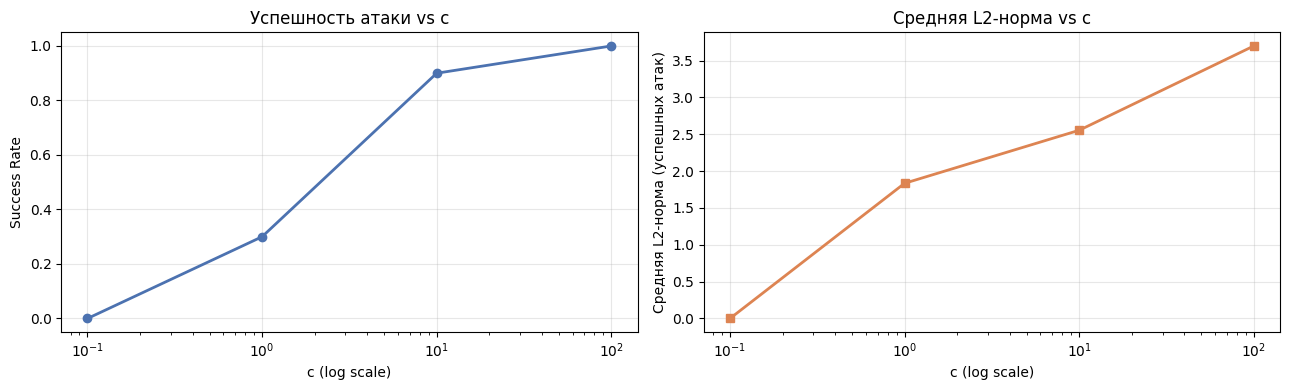

In [ ]:
# C4

c_values = [0.1, 1.0, 10.0, 100.0]
n_trials = 10
kappa = 0
num_steps = 300
lr = 0.05

# Возьмём 10 разных примеров из test_loader
x_trials, y_trials = get_eval_subset(test_loader, n_trials)

success_rates, avg_l2 = [], []

for c_val in c_values:
    succ, l2_list = 0, []
    for i in range(n_trials):
        x_i = x_trials[i:i+1]
        y_i = y_trials[i].item()
        # целевой класс = (истинный + 1) % 10 — отличный от истинного
        t_i = (y_i + 1) % 10

        x_cw = cw_l2_attack(model, x_i, t_i,
                            c=c_val, kappa=kappa,
                            num_steps=num_steps, lr=lr)

        with torch.no_grad():
            pred = model(x_cw).argmax(1).item()
        if pred == t_i:
            succ += 1
            l2_val = ((x_cw - x_i) ** 2).sum().sqrt().item()
            l2_list.append(l2_val)

    sr = succ / n_trials
    mean_l2 = np.mean(l2_list) if l2_list else 0.0
    success_rates.append(sr)
    avg_l2.append(mean_l2)
    print(f"c={c_val:>6} | SR={sr:.2f} | avg L2={mean_l2:.4f}")

# Графики
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(c_values, success_rates, marker='o', color='#4C72B0', linewidth=2)
axes[0].set_xscale('log')
axes[0].set_xlabel("c (log scale)")
axes[0].set_ylabel("Success Rate")
axes[0].set_title("Успешность атаки vs c")
axes[0].grid(alpha=0.3)
axes[0].set_ylim(-0.05, 1.05)

axes[1].plot(c_values, avg_l2, marker='s', color='#DD8452', linewidth=2)
axes[1].set_xscale('log')
axes[1].set_xlabel("c (log scale)")
axes[1].set_ylabel("Средняя L2-норма (успешных атак)")
axes[1].set_title("Средняя L2-норма vs c")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---

## Требования к сдаче
- Ноутбук выполняется целиком без ошибок (Kernel → Restart & Run All).
- Все `# TODO` заполнены, все вопросы для отчёта содержат письменный ответ.
- Обязательны: реализация PGD с проекцией, реализация C&W с замерами κ, реализация JSMA на основе якобиана, итоговая сравнительная таблица трёх атак.
